## **ML Assignment 2 by Mayank Ranjan**

## *Insurance Claims Data - Fraud Detection* using 5 ML models ##

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

The data has been sourced from Kaggle: https://www.kaggle.com/code/niteshyadav3103/insurance-fraud-detection-using-12-models/input

In [3]:
df_main_data = pd.read_csv('insurance_claims.csv')

In [4]:
df_main_data.shape

(1000, 40)

In [5]:
df_main_data.head()

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,?,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


In [6]:
df_main_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           1000 non-null   int64  
 1   age                          1000 non-null   int64  
 2   policy_number                1000 non-null   int64  
 3   policy_bind_date             1000 non-null   object 
 4   policy_state                 1000 non-null   object 
 5   policy_csl                   1000 non-null   object 
 6   policy_deductable            1000 non-null   int64  
 7   policy_annual_premium        1000 non-null   float64
 8   umbrella_limit               1000 non-null   int64  
 9   insured_zip                  1000 non-null   int64  
 10  insured_sex                  1000 non-null   object 
 11  insured_education_level      1000 non-null   object 
 12  insured_occupation           1000 non-null   object 
 13  insured_hobbies    

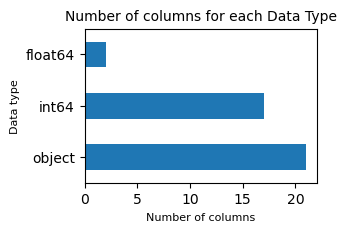

In [7]:
#Looking at the distribution of datatypes
plt.figure(figsize = (3,2))
df_main_data.dtypes.value_counts().plot(kind='barh')
plt.title('Number of columns for each Data Type',fontsize=10)
plt.xlabel('Number of columns',fontsize=8)
plt.ylabel('Data type',fontsize=8)
plt.show()

In [8]:
# A question mark can be seen in field police_report_available.
df_main_data['police_report_available'].unique()

array(['YES', '?', 'NO'], dtype=object)

In [9]:
#checking for special characters in the dataset and the fields containing them
special_chars = r'[^A-Za-z0-9\s]'

special_char_result = (
    df_main_data.astype(str)
      .apply(lambda c: sorted(set(''.join(c.str.findall(special_chars).explode().dropna()))))
)

# Keep only columns that actually have special characters
special_char_result = special_char_result[special_char_result.str.len() > 0]
print(special_char_result)

policy_bind_date           [-]
policy_csl                 [/]
policy_annual_premium      [.]
umbrella_limit             [-]
insured_occupation         [-]
insured_hobbies            [-]
insured_relationship       [-]
capital-loss               [-]
incident_date              [-]
incident_type              [-]
collision_type             [?]
property_damage            [?]
police_report_available    [?]
dtype: object


In [10]:
#some of the above fields have special characters which are required for the field, e.g. dates
#so we will only replace the cells with only special characters with NaN values
df_main_data.replace(r'^[^A-Za-z0-9\s]+$', np.nan, regex=True, inplace=True)

In [11]:
df_main_data.describe()

,months_as_customer,age,policy_number,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_year,_c39
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,0.0
mean,203.954000,38.948000,546238.648000,1136.000000,1256.406150,1.101000e+06,501214.488000,25126.100000,-26793.700000,11.644000,1.83900,0.992000,1.487000,52761.94000,7433.420000,7399.570000,37928.950000,2005.103000,NaN
std,115.113174,9.140287,257063.005276,611.864673,244.167395,2.297407e+06,71701.610941,27872.187708,28104.096686,6.951373,1.01888,0.820127,1.111335,26401.53319,4880.951853,4824.726179,18886.252893,6.015861,NaN
min,0.000000,19.000000,100804.000000,500.000000,433.330000,-1.000000e+06,430104.000000,0.000000,-111100.000000,0.000000,1.00000,0.000000,0.000000,100.00000,0.000000,0.000000,70.000000,1995.000000,NaN
25%,115.750000,32.000000,335980.250000,500.000000,1089.607500,0.000000e+00,448404.500000,0.000000,-51500.000000,6.000000,1.00000,0.000000,1.000000,41812.50000,4295.000000,4445.000000,30292.500000,2000.000000,NaN
50%,199.500000,38.000000,533135.000000,1000.000000,1257.200000,0.000000e+00,466445.500000,0.000000,-23250.000000,12.000000,1.00000,1.000000,1.000000,58055.00000,6775.000000,6750.000000,42100.000000,2005.000000,NaN
75%,276.250000,44.000000,759099.750000,2000.000000,1415.695000,0.000000e+00,603251.000000,51025.000000,0.000000,17.000000,3.00000,2.000000,2.000000,70592.50000,11305.000000,10885.000000,50822.500000,2010.000000,NaN
max,479.000000,64.000000,999435.000000,2000.000000,2047.590000,1.000000e+07,620962.000000,100500.000000,0.000000,23.000000,4.00000,2.000000,3.000000,114920.00000,21450.000000,23670.000000,79560.000000,2015.000000,NaN


In [12]:
#checking the fields with missing values
df_main_data.isna().sum()[lambda s: s > 0]


collision_type              178
authorities_contacted        91
property_damage             360
police_report_available     343
_c39                       1000
dtype: int64

In [13]:
#filling the missing values with mode of the respective columns
df_main_data = df_main_data.fillna(df_main_data.mode().iloc[0])

In [14]:
#finding difference between policy_bind_date and incident_date to create a new feature
df_main_data['policy_bind_date'] = pd.to_datetime(df_main_data['policy_bind_date'], errors='coerce') 
#error='coerce' will convert invalid parsing to NaT. NaT is the datetime equivalent of NaN, which is used to represent missing values in pandas.
df_main_data['incident_date'] = pd.to_datetime(df_main_data['incident_date'], errors='coerce')      
df_main_data['days_between_policy_and_incident'] = (df_main_data['incident_date'] - df_main_data['policy_bind_date']).dt.days

In [15]:
#dropping the columns which are not required for the analysis
columns_to_drop = ['policy_number','policy_bind_date','policy_state','insured_zip','incident_location','incident_date',
           'incident_state','incident_city','insured_hobbies','auto_make','auto_model','auto_year', '_c39']
df_main_data.drop(columns=columns_to_drop, inplace=True)

In [16]:
df_main_data.head()

,months_as_customer,age,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_sex,insured_education_level,insured_occupation,insured_relationship,...,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,fraud_reported,days_between_policy_and_incident
0,328,48,250/500,1000,1406.91,0,MALE,MD,craft-repair,husband,...,YES,1,2,YES,71610,6510,13020,52080,Y,100
1,228,42,250/500,2000,1197.22,5000000,MALE,MD,machine-op-inspct,other-relative,...,NO,0,0,NO,5070,780,780,3510,Y,3130
2,134,29,100/300,2000,1413.14,5000000,FEMALE,PhD,sales,own-child,...,NO,2,3,NO,34650,7700,3850,23100,N,5282
3,256,41,250/500,2000,1415.74,6000000,FEMALE,PhD,armed-forces,unmarried,...,NO,1,2,NO,63400,6340,6340,50720,Y,8996
4,228,44,500/1000,1000,1583.91,6000000,MALE,Associate,sales,unmarried,...,NO,0,1,NO,6500,1300,650,4550,N,256


In [17]:
df_main_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   months_as_customer                1000 non-null   int64  
 1   age                               1000 non-null   int64  
 2   policy_csl                        1000 non-null   object 
 3   policy_deductable                 1000 non-null   int64  
 4   policy_annual_premium             1000 non-null   float64
 5   umbrella_limit                    1000 non-null   int64  
 6   insured_sex                       1000 non-null   object 
 7   insured_education_level           1000 non-null   object 
 8   insured_occupation                1000 non-null   object 
 9   insured_relationship              1000 non-null   object 
 10  capital-gains                     1000 non-null   int64  
 11  capital-loss                      1000 non-null   int64  
 12  inciden

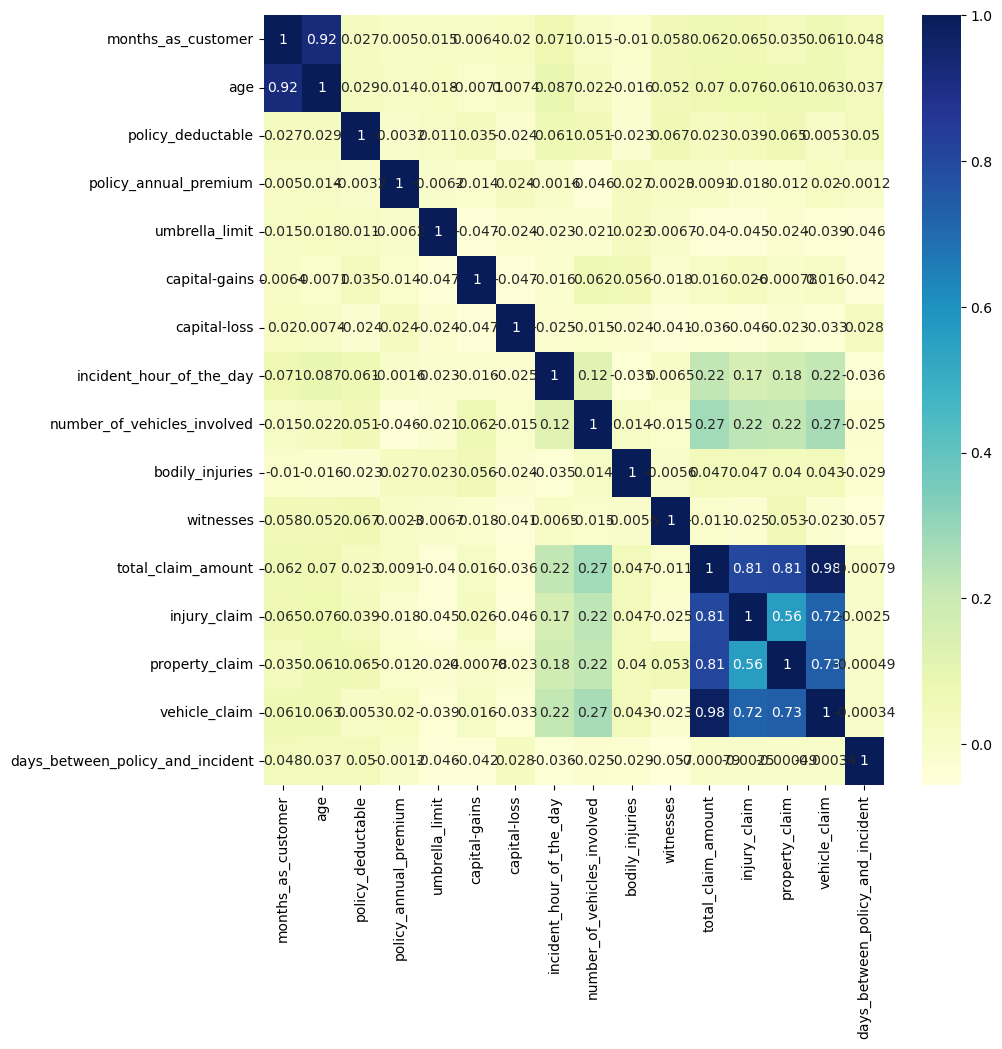

In [18]:
#heatmap to see clear correlation between variables
plt.figure(figsize = (10,10))
sns.heatmap(df_main_data.corr(numeric_only=True),cmap = 'YlGnBu', annot = True) 
plt.show()

 The fields "month as customer" and "age" are highly correlated. Therefore dropping "age". Fields "total_claim_amount" is highly correlated with
 other amounts like "vehicle_claim", "injury_claim", "property_claim". Therefore dropping "total_claim_amount"

In [19]:
df_main_data.drop(columns=['age','total_claim_amount'], inplace=True)

Data Preparation

In [20]:
df_main_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   months_as_customer                1000 non-null   int64  
 1   policy_csl                        1000 non-null   object 
 2   policy_deductable                 1000 non-null   int64  
 3   policy_annual_premium             1000 non-null   float64
 4   umbrella_limit                    1000 non-null   int64  
 5   insured_sex                       1000 non-null   object 
 6   insured_education_level           1000 non-null   object 
 7   insured_occupation                1000 non-null   object 
 8   insured_relationship              1000 non-null   object 
 9   capital-gains                     1000 non-null   int64  
 10  capital-loss                      1000 non-null   int64  
 11  incident_type                     1000 non-null   object 
 12  collisi

In [21]:
# separating the feature and target columns

X = df_main_data.drop('fraud_reported', axis = 1)
y = df_main_data['fraud_reported']
y = y.map({'Y': 1, 'N': 0, 'Yes': 1, 'No': 0}).astype(int)

In [22]:
# categotrical features extraction
categorical_df = X.select_dtypes(include = ['object'])

In [23]:
categorical_df.head()

,policy_csl,insured_sex,insured_education_level,insured_occupation,insured_relationship,incident_type,collision_type,incident_severity,authorities_contacted,property_damage,police_report_available
0,250/500,MALE,MD,craft-repair,husband,Single Vehicle Collision,Side Collision,Major Damage,Police,YES,YES
1,250/500,MALE,MD,machine-op-inspct,other-relative,Vehicle Theft,Rear Collision,Minor Damage,Police,NO,NO
2,100/300,FEMALE,PhD,sales,own-child,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NO,NO
3,250/500,FEMALE,PhD,armed-forces,unmarried,Single Vehicle Collision,Front Collision,Major Damage,Police,NO,NO
4,500/1000,MALE,Associate,sales,unmarried,Vehicle Theft,Rear Collision,Minor Damage,Police,NO,NO


In [24]:
# one hot encoding of categorical features
categorical_df = pd.get_dummies(categorical_df, drop_first=True)

In [25]:
print(categorical_df.shape)
categorical_df.head(2)

(1000, 40)


,policy_csl_250/500,policy_csl_500/1000,insured_sex_MALE,insured_education_level_College,insured_education_level_High School,insured_education_level_JD,insured_education_level_MD,insured_education_level_Masters,insured_education_level_PhD,insured_occupation_armed-forces,...,collision_type_Rear Collision,collision_type_Side Collision,incident_severity_Minor Damage,incident_severity_Total Loss,incident_severity_Trivial Damage,authorities_contacted_Fire,authorities_contacted_Other,authorities_contacted_Police,property_damage_YES,police_report_available_YES
0,True,False,True,False,False,False,True,False,False,False,...,False,True,False,False,False,False,False,True,True,True
1,True,False,True,False,False,False,True,False,False,False,...,True,False,True,False,False,False,False,True,False,False


In [26]:
# extracting the numerical columns

numerical_df = X.select_dtypes(include = ['int64', 'float64']) 
#include is used to specify the data types to include in the selection. 
# In this case, we are selecting columns with data types int64 and float64, which represent numerical features.

In [27]:
#combining the numerical and categorical features to create the final feature set
X = pd.concat([numerical_df, categorical_df], axis=1)

In [28]:
print(X.shape)
X.head()

(1000, 54)


,months_as_customer,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,...,collision_type_Rear Collision,collision_type_Side Collision,incident_severity_Minor Damage,incident_severity_Total Loss,incident_severity_Trivial Damage,authorities_contacted_Fire,authorities_contacted_Other,authorities_contacted_Police,property_damage_YES,police_report_available_YES
0,328,1000,1406.91,0,53300,0,5,1,1,2,...,False,True,False,False,False,False,False,True,True,True
1,228,2000,1197.22,5000000,0,0,8,1,0,0,...,True,False,True,False,False,False,False,True,False,False
2,134,2000,1413.14,5000000,35100,0,7,3,2,3,...,True,False,True,False,False,False,False,True,False,False
3,256,2000,1415.74,6000000,48900,-62400,5,1,1,2,...,False,False,False,False,False,False,False,True,False,False
4,228,1000,1583.91,6000000,66000,-46000,20,1,0,1,...,True,False,True,False,False,False,False,True,False,False


In [29]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 54 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   months_as_customer                      1000 non-null   int64  
 1   policy_deductable                       1000 non-null   int64  
 2   policy_annual_premium                   1000 non-null   float64
 3   umbrella_limit                          1000 non-null   int64  
 4   capital-gains                           1000 non-null   int64  
 5   capital-loss                            1000 non-null   int64  
 6   incident_hour_of_the_day                1000 non-null   int64  
 7   number_of_vehicles_involved             1000 non-null   int64  
 8   bodily_injuries                         1000 non-null   int64  
 9   witnesses                               1000 non-null   int64  
 10  injury_claim                            1000 non-null   int64

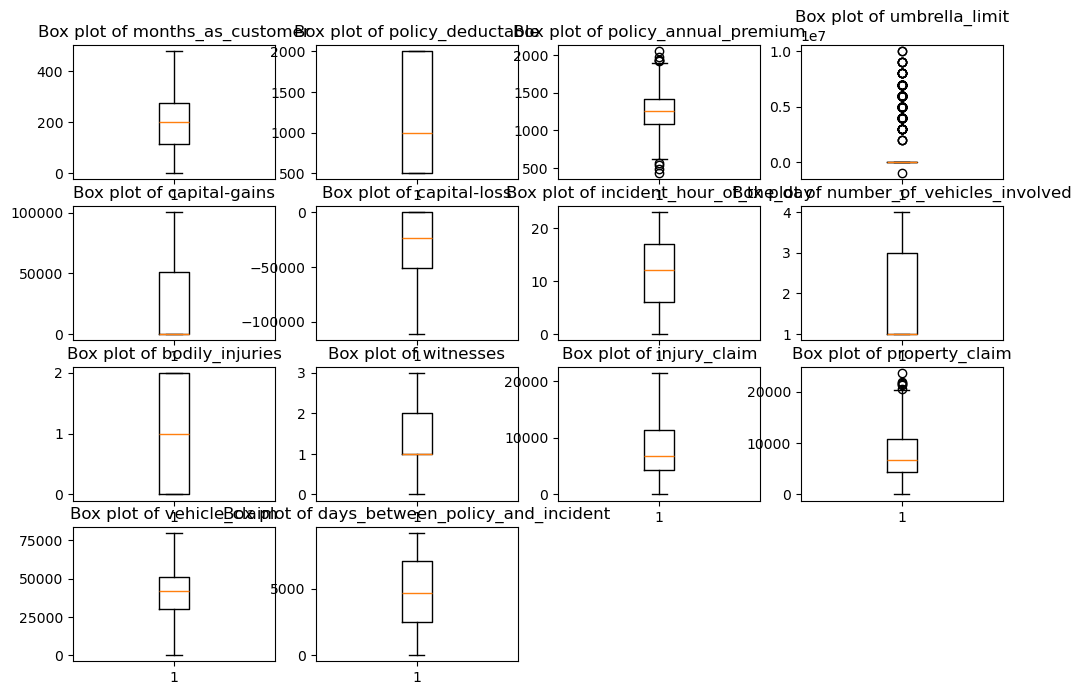

In [30]:
#box plot to check for outliers in the numerical features
plt.figure(figsize=(12, 8))
for i, col in enumerate(numerical_df): 
    #enumerate() function is used to iterate over the columns of the DataFrame X. 
    # It returns both the index (i) and the column name (col) for each iteration.
    plt.subplot(4, 4, i + 1)
    plt.boxplot(numerical_df[col])
    plt.title(f'Box plot of {col}') 
plt.show()

Outliers exist in some features. After splitting the test train dataset, scale every numerical feature

In [31]:
#test train split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(800, 54) (200, 54)


In [32]:
#only standardaize the columns with continuous values
#not standardizing columns with binary or one hot encoded values
continuous_cols =  ['months_as_customer', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit',
       'capital-gains', 'capital-loss', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'bodily_injuries', 'witnesses', 'injury_claim', 'property_claim',
       'vehicle_claim','days_between_policy_and_incident']

binary_and_dummy_cols = [c for c in X_train.columns if c not in continuous_cols]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])  # transform only, no fit

In [33]:
X_train_scaled.describe()

,months_as_customer,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,injury_claim,property_claim,vehicle_claim,days_between_policy_and_incident
count,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02
mean,1.221245e-17,3.108624e-17,3.441691e-16,-1.110223e-17,-1.332268e-17,-8.881784e-18,6.328271e-17,1.176836e-16,-5.107026e-17,-5.551115e-18,-1.110223e-18,-6.661338e-17,1.443290e-16,2.220446e-17
std,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00
min,-1.785764e+00,-1.041729e+00,-3.414656e+00,-9.209267e-01,-8.870779e-01,-3.028406e+00,-1.676714e+00,-8.217921e-01,-1.202225e+00,-1.349038e+00,-1.491306e+00,-1.498540e+00,-1.867428e+00,-1.764942e+00
25%,-7.725244e-01,-1.041729e+00,-6.647277e-01,-4.776407e-01,-8.870779e-01,-8.779188e-01,-8.071053e-01,-8.217921e-01,-1.202225e+00,-4.436433e-01,-6.691581e-01,-6.248961e-01,-4.402732e-01,-8.517151e-01
50%,-1.751833e-02,-2.349689e-01,3.138288e-02,-4.776407e-01,-8.870779e-01,1.897181e-01,6.250310e-02,-8.217921e-01,6.041331e-03,-4.436433e-01,-1.412845e-01,-1.277168e-01,2.220012e-01,-2.044731e-03
75%,6.302550e-01,1.378552e+00,6.143986e-01,-4.776407e-01,9.346729e-01,9.486084e-01,7.871768e-01,1.140697e+00,1.214308e+00,4.617512e-01,8.001910e-01,7.397896e-01,6.885212e-01,8.618008e-01
max,2.407255e+00,1.378552e+00,3.267790e+00,3.955220e+00,2.745580e+00,9.486084e-01,1.656785e+00,2.121941e+00,1.214308e+00,1.367146e+00,2.846965e+00,3.344355e+00,2.180841e+00,1.641522e+00


In [34]:
X_train_scaled.describe()

,months_as_customer,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,injury_claim,property_claim,vehicle_claim,days_between_policy_and_incident
count,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02
mean,1.221245e-17,3.108624e-17,3.441691e-16,-1.110223e-17,-1.332268e-17,-8.881784e-18,6.328271e-17,1.176836e-16,-5.107026e-17,-5.551115e-18,-1.110223e-18,-6.661338e-17,1.443290e-16,2.220446e-17
std,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00
min,-1.785764e+00,-1.041729e+00,-3.414656e+00,-9.209267e-01,-8.870779e-01,-3.028406e+00,-1.676714e+00,-8.217921e-01,-1.202225e+00,-1.349038e+00,-1.491306e+00,-1.498540e+00,-1.867428e+00,-1.764942e+00
25%,-7.725244e-01,-1.041729e+00,-6.647277e-01,-4.776407e-01,-8.870779e-01,-8.779188e-01,-8.071053e-01,-8.217921e-01,-1.202225e+00,-4.436433e-01,-6.691581e-01,-6.248961e-01,-4.402732e-01,-8.517151e-01
50%,-1.751833e-02,-2.349689e-01,3.138288e-02,-4.776407e-01,-8.870779e-01,1.897181e-01,6.250310e-02,-8.217921e-01,6.041331e-03,-4.436433e-01,-1.412845e-01,-1.277168e-01,2.220012e-01,-2.044731e-03
75%,6.302550e-01,1.378552e+00,6.143986e-01,-4.776407e-01,9.346729e-01,9.486084e-01,7.871768e-01,1.140697e+00,1.214308e+00,4.617512e-01,8.001910e-01,7.397896e-01,6.885212e-01,8.618008e-01
max,2.407255e+00,1.378552e+00,3.267790e+00,3.955220e+00,2.745580e+00,9.486084e-01,1.656785e+00,2.121941e+00,1.214308e+00,1.367146e+00,2.846965e+00,3.344355e+00,2.180841e+00,1.641522e+00


In [35]:
X_test_scaled.describe()

,months_as_customer,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,witnesses,injury_claim,property_claim,vehicle_claim,days_between_policy_and_incident
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,-0.002068,-0.077651,-0.037107,0.052086,0.105632,-0.052590,0.054532,0.007359,-0.018124,-0.013581,0.060531,0.077078,0.117359,-0.006258
std,1.037909,0.931675,1.052399,1.088275,1.032593,1.028856,1.035928,0.998826,0.953469,1.030661,0.932260,0.931103,0.881715,0.977515
min,-1.750750,-1.041729,-2.864995,-0.477641,-0.887078,-2.401964,-1.676714,-0.821792,-1.202225,-1.349038,-1.491306,-1.498540,-1.938423,-1.755306
25%,-0.761582,-1.041729,-0.764472,-0.477641,-0.887078,-1.009472,-0.952040,-0.821792,-1.202225,-1.349038,-0.441626,-0.420296,-0.223531,-0.786955
50%,-0.144447,-0.234969,-0.111207,-0.477641,0.078016,-0.021483,0.207438,-0.821792,0.006041,-0.443643,-0.058362,-0.074521,0.261644,-0.032433
75%,0.667458,1.378552,0.788139,-0.477641,0.993410,0.948608,0.823410,1.140697,1.214308,1.367146,0.741538,0.700915,0.717671,0.874679
max,2.407255,1.378552,2.644030,3.955220,2.322674,0.948608,1.656785,2.121941,1.214308,1.367146,2.064256,2.926969,2.082899,1.623734


# ***Models***


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, roc_auc_score,\
      precision_score, recall_score, f1_score, matthews_corrcoef



# Logistic Regression

In [37]:
# Logistic Regression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
    #max_iter = 1000 is set to ensure that the optimization algorithm has enough iterations to converge.
log_reg.fit(X_train_scaled, y_train)

log_reg_pred = log_reg.predict(X_test_scaled)
#Ipredictt returns the predicted class labels for the input data.
log_reg_score = log_reg.predict_proba(X_test_scaled)[:, 1]  
# predict_proba returns the probability estimates for each class. 
# The output is an array of shape (n_samples, n_classes), 
# where n_samples is the number of samples in the input data and n_classes is the number of classes 
# in the target variable. Each row of the array corresponds to a sample, 
# and each column corresponds to a class. The values in the array represent the 
# predicted probabilities of each class for each sample. 
# In this case, I am interested in the probability of the positive class (class 1), 
# so selected the second column (index 1) using [:, 1].

log_reg_accuracy = accuracy_score(y_test, log_reg_pred)
log_reg_auc = roc_auc_score(y_test, log_reg_score)
log_reg_precision = precision_score(y_test, log_reg_pred, zero_division=0)
log_reg_recall = recall_score(y_test, log_reg_pred, zero_division=0)
log_reg_f1 = f1_score(y_test, log_reg_pred, zero_division=0)
log_reg_mcc = matthews_corrcoef(y_test, log_reg_pred)

print("Logistic Regression")
metrics_log_reg = {
    "Accuracy": log_reg_accuracy,
    " AUC Score": log_reg_auc,
    "Precision": log_reg_precision,
    "Recall": log_reg_recall,
    "F1 Score": log_reg_f1,
    "MCC Score": log_reg_mcc,
}

for name, value in metrics_log_reg.items():
    print(f"{name}: {value:.4f}")


Logistic Regression
Accuracy: 0.8350
 AUC Score: 0.7986
Precision: 0.7000
Recall: 0.5714
F1 Score: 0.6292
MCC Score: 0.5290


In [38]:
# Decision Tree Classifier


dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

dt_pred = dt_model.predict(X_test_scaled)
dt_score = dt_model.predict_proba(X_test_scaled)[:, 1]

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_auc = roc_auc_score(y_test, dt_score)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)
dt_mcc = matthews_corrcoef(y_test, dt_pred)

print("Decision Tree Classifier")
metrics_dec_tree = {
    "Accuracy": dt_accuracy,
    "AUC Score": dt_auc,
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1 Score": dt_f1,
    "MCC Score": dt_mcc,
}

for name, value in metrics_dec_tree.items():
    print(f"{name}: {value:.4f}")

Decision Tree Classifier
Accuracy: 0.6950
AUC Score: 0.5706
Precision: 0.3636
Recall: 0.3265
F1 Score: 0.3441
MCC Score: 0.1465


In [39]:
# K-Nearest Neighbor Classifier


knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)
knn_score = knn_model.predict_proba(X_test_scaled)[:, 1]

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_auc = roc_auc_score(y_test, knn_score)
knn_precision = precision_score(y_test, knn_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_pred, zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, zero_division=0)
knn_mcc = matthews_corrcoef(y_test, knn_pred)

print("K-Nearest Neighbor Classifier")
metrics_knn = {
    "Accuracy": knn_accuracy,
    "AUC Score": knn_auc,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1 Score": knn_f1,
    "MCC Score": knn_mcc,
}

for name, value in metrics_knn.items():
    print(f"{name}: {value:.4f}")

K-Nearest Neighbor Classifier
Accuracy: 0.7200
AUC Score: 0.6329
Precision: 0.3600
Recall: 0.1837
F1 Score: 0.2432
MCC Score: 0.1011


In [40]:
# Naive Bayes Classifier


nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

nb_pred = nb_model.predict(X_test_scaled)
nb_score = nb_model.predict_proba(X_test_scaled)[:, 1]

nb_accuracy = accuracy_score(y_test, nb_pred)
nb_auc = roc_auc_score(y_test, nb_score)
nb_precision = precision_score(y_test, nb_pred, zero_division=0)
nb_recall = recall_score(y_test, nb_pred, zero_division=0)
nb_f1 = f1_score(y_test, nb_pred, zero_division=0)
nb_mcc = matthews_corrcoef(y_test, nb_pred)

print("Naive Bayes Classifier")
metrics_nv = {
    "Accuracy": nb_accuracy,
    "AUC Score": nb_auc,
    "Precision": nb_precision,
    "Recall": nb_recall,
    "F1 Score": nb_f1,
    "MCC Score": nb_mcc,
}

for name, value in metrics_nv.items():
    print(f"{name}: {value:.4f}")

Naive Bayes Classifier
Accuracy: 0.5900
AUC Score: 0.7058
Precision: 0.3429
Recall: 0.7347
F1 Score: 0.4675
MCC Score: 0.2392


In [41]:
# Support Vector Machine


svm_model = SVC(kernel="rbf", probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)
svm_score = svm_model.predict_proba(X_test_scaled)[:, 1]

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_auc = roc_auc_score(y_test, svm_score)
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)
svm_mcc = matthews_corrcoef(y_test, svm_pred)

print("Support Vector Machine")
metrics_svm = {
    "Accuracy": svm_accuracy,
    "AUC Score": svm_auc,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1 Score": svm_f1,
    "MCC Score": svm_mcc,
}

for name, value in metrics_svm.items():
    print(f"{name}: {value:.4f}")

Support Vector Machine
Accuracy: 0.7650
AUC Score: 0.7948
Precision: 0.7500
Recall: 0.0612
F1 Score: 0.1132
MCC Score: 0.1677


In [42]:
# Summary of model performance

summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree Classifier",
        "K-Nearest Neighbor Classifier",
        "Naive Bayes Classifier",
        "Support Vector Machine",
    ],
    "Accuracy": [
        log_reg_accuracy, dt_accuracy, knn_accuracy, nb_accuracy, svm_accuracy
    ],
    "AUC Score": [
        log_reg_auc, dt_auc, knn_auc, nb_auc, svm_auc
    ],
    "Precision": [
        log_reg_precision, dt_precision, knn_precision, nb_precision, svm_precision
    ],
    "Recall": [
        log_reg_recall, dt_recall, knn_recall, nb_recall, svm_recall
    ],
    "F1 Score": [
        log_reg_f1, dt_f1, knn_f1, nb_f1, svm_f1
    ],
    "MCC Score": [
        log_reg_mcc, dt_mcc, knn_mcc, nb_mcc, svm_mcc
    ],
})

print(summary.to_string(index=False))


                        Model  Accuracy  AUC Score  Precision   Recall  F1 Score  MCC Score
          Logistic Regression     0.835   0.798621   0.700000 0.571429  0.629213   0.528962
     Decision Tree Classifier     0.695   0.570550   0.363636 0.326531  0.344086   0.146496
K-Nearest Neighbor Classifier     0.720   0.632923   0.360000 0.183673  0.243243   0.101063
       Naive Bayes Classifier     0.590   0.705771   0.342857 0.734694  0.467532   0.239204
       Support Vector Machine     0.765   0.794770   0.750000 0.061224  0.113208   0.167740


In [43]:
# Observations for each model based on the test-set metrics
observations = {
    "Logistic Regression": (
        "Best overall performer: highest accuracy (83.5%), AUC (0.7986), F1 (0.6292), "
        "and MCC (0.5290). It provides the best balance between detecting fraud and "
        "avoiding false alarms."
    ),
    "Decision Tree Classifier": (
        "Weak performance overall: accuracy is 69.5% and AUC is 0.5706. Its low F1 "
        "score (0.3441) and MCC (0.1465) indicate limited and imbalanced fraud detection."
    ),
    "K-Nearest Neighbor Classifier": (
        "Moderate accuracy (72.0%), but poor fraud detection: recall is only 18.37% "
        "and F1 is 0.2432. It misses most fraudulent claims in this configuration."
    ),
    "Naive Bayes Classifier": (
        "Best at finding fraudulent claims: highest recall (73.47%), but it produces "
        "many false positives, resulting in the lowest accuracy (59.0%) and modest F1 (0.4675)."
    ),
    "Support Vector Machine": (
        "Good ranking ability (AUC 0.7948) and precision (75.0%), but extremely low "
        "recall (6.12%) and F1 (0.1132) mean that it misses almost all fraudulent claims."
    ),
}

observation_table = summary[[
    "Model", "Accuracy", "AUC Score", "Precision", "Recall", "F1 Score", "MCC Score"
]].copy()

observation_table["Observation"] = observation_table["Model"].map(observations)

(observation_table[["Model", "Observation"]]
    .style
    .set_properties(subset=["Observation"], **{
        "white-space": "normal",
        "text-align": "left",
        "max-width": "600px",
    })
    .hide(axis="index")
)
# for metric in ["Accuracy", "AUC Score", "Precision", "Recall", "F1 Score", "MCC Score"]:
#     observation_table[metric] = observation_table[metric].map(lambda value: f"{value:.4f}")
# observation_table


Model,Observation
Logistic Regression,"Best overall performer: highest accuracy (83.5%), AUC (0.7986), F1 (0.6292), and MCC (0.5290). It provides the best balance between detecting fraud and avoiding false alarms."
Decision Tree Classifier,Weak performance overall: accuracy is 69.5% and AUC is 0.5706. Its low F1 score (0.3441) and MCC (0.1465) indicate limited and imbalanced fraud detection.
K-Nearest Neighbor Classifier,"Moderate accuracy (72.0%), but poor fraud detection: recall is only 18.37% and F1 is 0.2432. It misses most fraudulent claims in this configuration."
Naive Bayes Classifier,"Best at finding fraudulent claims: highest recall (73.47%), but it produces many false positives, resulting in the lowest accuracy (59.0%) and modest F1 (0.4675)."
Support Vector Machine,"Good ranking ability (AUC 0.7948) and precision (75.0%), but extremely low recall (6.12%) and F1 (0.1132) mean that it misses almost all fraudulent claims."


In [44]:
# Overall winner based on the fraud-detection metrics
# F1 score is the primary criterion because it balances precision and recall.
# MCC and accuracy are used as deterministic tie-breakers.
winner = summary.sort_values(
    by=["F1 Score", "MCC Score", "Accuracy"],
    ascending=False,
).iloc[0]

model_objects = {
    "Logistic Regression": log_reg,
    "Decision Tree Classifier": dt_model,
    "K-Nearest Neighbor Classifier": knn_model,
    "Naive Bayes Classifier": nb_model,
    "Support Vector Machine": svm_model,
}

overall_winner_model = model_objects[winner["Model"]]
print(f"Overall winner: {winner['Model']}")
print(winner[["Accuracy", "AUC Score", "Precision", "Recall", "F1 Score", "MCC Score"]].to_string())

Overall winner: Logistic Regression
Accuracy        0.835
AUC Score    0.798621
Precision         0.7
Recall       0.571429
F1 Score     0.629213
MCC Score    0.528962


In [45]:
# Export the held-out test features and labels for the Streamlit application.
# Keeping the target enables the app to calculate evaluation metrics without retraining.
test_data_for_app = X_test_scaled.reset_index(drop=True).copy()
test_data_for_app["fraud_reported"] = y_test.reset_index(drop=True)
test_data_for_app.to_csv("insurance_claims_test.csv", index=False)
print(f"Saved {len(test_data_for_app)} labeled test rows to insurance_claims_test.csv")

Saved 200 labeled test rows to insurance_claims_test.csv
